# ☕ Café Sales 2023: Data Cleaning and EDA

**Goal:** turn a deliberately "dirty" sales file of a café into a clean table and answer the owner's questions:
what drives revenue, is there seasonality, and how reliable is the data from the till?

**Result:** 9,514 of 10,000 transactions are usable; revenue 2023 = $84,868.50, average check = $8.92.
Interactive dashboard (German): see the project [README](../README.md).

**Steps:** 1 · First look → 2 · Cleaning → 3 · EDA → 4 · Summary for the owner

*Charts follow the German reporting standard (IBCS): German labels, title = key message, German number format.*

## About the data

Kaggle dataset **Cafe Sales – Dirty Data for Cleaning Training**: 10,000 synthetic café transactions in 2023,
intentionally damaged with gaps and the words `ERROR` / `UNKNOWN` instead of values.

| Column | Content |
|---|---|
| `Transaction ID` | unique transaction number |
| `Item` | product: coffee, tea, cake, … |
| `Quantity` | units of the product |
| `Price Per Unit` | price per unit, $ |
| `Total Spent` | transaction amount, $ (= quantity × price) |
| `Payment Method` | cash, credit card, digital wallet |
| `Location` | in-store or takeaway |
| `Transaction Date` | date of sale |

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# input: raw "dirty" file; output: clean table for Tableau
FILE_IN = "https://raw.githubusercontent.com/SergiiVdovenkov/Cafe_sales/main/Data/dirty_cafe_sales.csv"
FILE_OUT = "cafe_sales_clean.csv"

# one chart style for the whole notebook
BLUE, GREY, ORANGE = "#4E79A7", "#D3D3D3", "#F28E2B"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "text.parse_math": False,   # "$" in titles is plain text, not math
})

def de(x, d=0):
    """German number format: 1.234,5"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

print("Ready!")

Ready!


---
# 1 · First look
Before fixing anything, find out **what exactly** is wrong with the data.

### 1.1 Load and inspect

In [2]:
# raw file stays untouched; all changes go to the working copy df
df_original = pd.read_csv(FILE_IN)
df = df_original.copy()

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head(10))
df.info()

Rows: 10000 | Columns: 8


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


**Finding:** `Quantity`, `Price Per Unit`, `Total Spent` should be numbers and `Transaction Date` a date,
but all are stored as text, because the columns also contain the words `ERROR` and `UNKNOWN`.

### 1.2 What kind of "garbage" is in the data?

In [3]:
# text columns: all values with counts, including empty cells (NaN)
for col in ["Item", "Payment Method", "Location"]:
    display(df[col].value_counts(dropna=False))

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64

Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64

In [4]:
# numeric columns: values that were filled but cannot be read as a number
for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "->", df.loc[converted.isna() & df[col].notna(), col].unique())

# same check for the date
converted = pd.to_datetime(df["Transaction Date"], errors="coerce")
print("Transaction Date ->",
      df.loc[converted.isna() & df["Transaction Date"].notna(), "Transaction Date"].unique())

Quantity -> <StringArray>
['ERROR', 'UNKNOWN']
Length: 2, dtype: str
Price Per Unit -> <StringArray>
['ERROR', 'UNKNOWN']
Length: 2, dtype: str
Total Spent -> <StringArray>
['ERROR', 'UNKNOWN']
Length: 2, dtype: str
Transaction Date -> <StringArray>
['ERROR', 'UNKNOWN']
Length: 2, dtype: str


In [5]:
# how often ERROR / UNKNOWN appear per column
display(df.isin(["ERROR", "UNKNOWN"]).sum())

Transaction ID        0
Item                636
Quantity            341
Price Per Unit      354
Total Spent         329
Payment Method      599
Location            696
Transaction Date    301
dtype: int64

**Finding:** `Item` is damaged in 969 of 10,000 rows (9.7 %: 344 UNKNOWN + 333 empty + 292 ERROR).
Numeric and date columns contain only `ERROR` and `UNKNOWN` as non-values, no commas or currency signs,
so these values simply become missing values.

### 1.3 Duplicates

In [6]:
print("Full duplicates:", df.duplicated().sum())
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())

# remove full duplicates (none found, kept as a standard step)
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Full duplicates: 0
Repeated transaction IDs: 0
Rows after removing duplicates: 10000


### 1.4 Missing values

In [7]:
# placeholder words -> real empty cells
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

# missing values per column: count and %
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "pct": missing_pct})
display(missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False))

,missing,pct
Location,3961,39.6
Payment Method,3178,31.8
Item,969,9.7
Price Per Unit,533,5.3
Total Spent,502,5.0
Quantity,479,4.8
Transaction Date,460,4.6


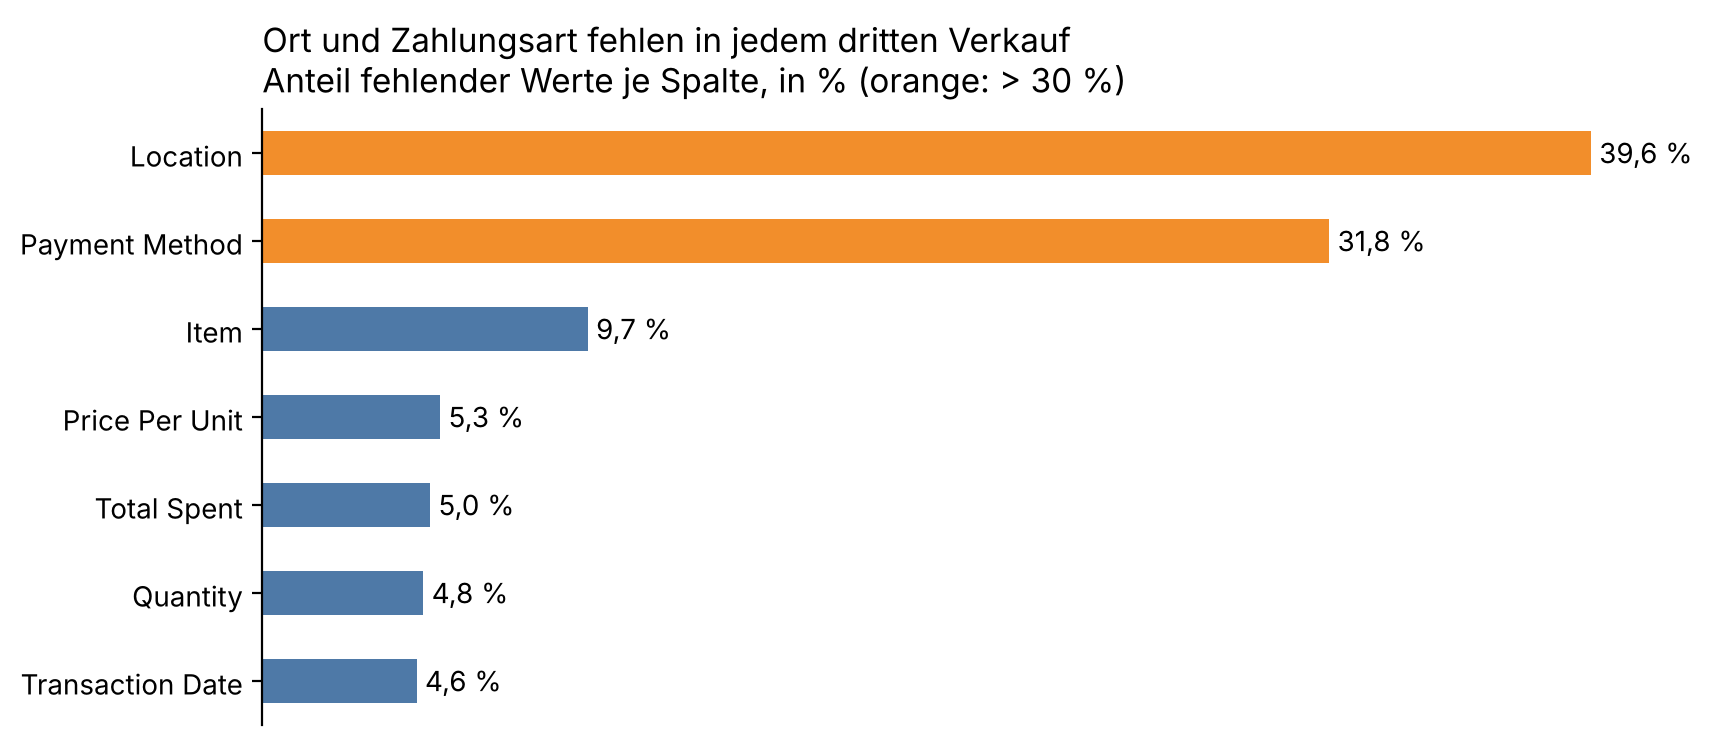

In [8]:
# chart: share of missing values per column
s = missing_pct[missing_pct > 0].sort_values()
ax = s.plot(kind="barh", color=[ORANGE if v > 30 else BLUE for v in s])
ax.bar_label(ax.containers[0], labels=[de(v, 1) + " %" for v in s], padding=3)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
plt.title("Ort und Zahlungsart fehlen in jedem dritten Verkauf\n"
          "Anteil fehlender Werte je Spalte, in % (orange: > 30 %)", loc="left")
plt.ylabel("")
plt.show()

**Finding:**
- Most gaps: `Location` (39.6 %) and `Payment Method` (31.8 %). They cannot be derived from other columns, so they get the label `Unknown`.
- `Quantity`, `Price Per Unit`, `Total Spent` (4.8–5.3 %) can be restored with *total = quantity × price* and the fixed menu price.
- `Item` (9.7 %) can be partly restored from the price, if the price belongs to only one item.
- `Transaction Date` (4.6 %) cannot be restored: these rows will be removed.

---
# 2 · Cleaning
Rule: **first restore what can be calculated exactly, then fill the rest.** Every invented value distorts the analysis.

### 2.1 Column names to `snake_case`

In [9]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
print(list(df.columns))

['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'transaction_date']


### 2.2 Correct data types

In [10]:
for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

df.info()
display(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  str           
 1   item              9031 non-null   str           
 2   quantity          9521 non-null   float64       
 3   price_per_unit    9467 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   str           
 6   location          6039 non-null   str           
 7   transaction_date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 625.1 KB


transaction_id         0
item                 969
quantity             479
price_per_unit       533
total_spent          502
payment_method      3178
location            3961
transaction_date     460
dtype: int64

### 2.3 Restore numbers exactly
Two hard rules: **total = quantity × price**, and every item has a fixed menu price.

In [11]:
# 1. check: one price per item?
display(df.groupby("item")["price_per_unit"].nunique())

# 2. lookup "item -> price"
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print(price_of_item)

# 3a. price from item
mask = df["price_per_unit"].isna() & df["item"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Price from item:", mask.sum())

# 3b. price = total / quantity
mask = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Price = total / quantity:", mask.sum())

# 3c. quantity = total / price, rounded to an integer
mask = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Quantity = total / price:", mask.sum())

# 3d. total = quantity * price
mask = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Total = quantity * price:", mask.sum())

# 4. check the formula and remaining gaps
check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Mismatches:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())

item
Cake        1
Coffee      1
Cookie      1
Juice       1
Salad       1
Sandwich    1
Smoothie    1
Tea         1
Name: price_per_unit, dtype: int64

{'Cake': 3.0, 'Coffee': 2.0, 'Cookie': 1.0, 'Juice': 3.0, 'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Tea': 1.5}
Price from item: 479
Price = total / quantity: 48
Quantity = total / price: 456
Total = quantity * price: 479
Mismatches: 0


quantity          23
price_per_unit     6
total_spent       23
dtype: int64

### 2.4 Restore the item from a unique price

In [12]:
# which items are sold at each price (rows with a known item only)
known_items = df.dropna(subset=["item"])
display(known_items.groupby("price_per_unit")["item"].unique())

# prices that belong to exactly ONE item -> lookup "price -> item"
n_items = known_items.groupby("price_per_unit")["item"].nunique()
unique_prices = n_items[n_items == 1].index
item_of_price = (known_items[known_items["price_per_unit"].isin(unique_prices)]
                 .groupby("price_per_unit")["item"].first().to_dict())
print(item_of_price)

# fill the item where it is empty and the price is unique
mask = df["item"].isna() & df["price_per_unit"].isin(unique_prices)
df.loc[mask, "item"] = df.loc[mask, "price_per_unit"].map(item_of_price)
print("Item from unique price:", mask.sum())
print("Item still missing:", df["item"].isna().sum())
print(df.loc[df["item"].isna(), "price_per_unit"].value_counts(dropna=False))

price_per_unit
1.0                [Cookie]
1.5                   [Tea]
2.0                [Coffee]
3.0           [Cake, Juice]
4.0    [Smoothie, Sandwich]
5.0                 [Salad]
Name: item, dtype: object

{1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}
Item from unique price: 489
Item still missing: 480
price_per_unit
3.0    247
4.0    227
NaN      6
Name: count, dtype: int64


**Finding:** two prices are ambiguous: $3.00 = Cake or Juice, $4.00 = Sandwich or Smoothie.
489 items restored from a unique price; 480 rows still without an item (247 at $3.00, 227 at $4.00, 6 without a price).

### 2.5 Can other columns help to guess the item?

In [13]:
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5

for pair_items in [["Cake", "Juice"], ["Sandwich", "Smoothie"]]:
    pair = df[df["item"].isin(pair_items)]
    print(pair_items)
    # overall share of each item, %
    display(pair["item"].value_counts(normalize=True) * 100)
    # shares by location, %
    display(pd.crosstab(pair["location"], pair["item"], normalize="index") * 100)
    # shares weekday vs weekend, rows with a known date only, %
    pair_dated = pair[pair["transaction_date"].notna()]
    display(pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100)

['Cake', 'Juice']


item
Juice    50.692641
Cake     49.307359
Name: proportion, dtype: float64

item,Cake,Juice
location,,
In-store,47.067449,52.932551
Takeaway,50.146199,49.853801


item,Cake,Juice
is_weekend,,
False,49.527410,50.472590
True,47.819063,52.180937


['Sandwich', 'Smoothie']


item
Sandwich    50.785811
Smoothie    49.214189
Name: proportion, dtype: float64

item,Sandwich,Smoothie
location,,
In-store,53.468208,46.531792
Takeaway,53.158706,46.841294


item,Sandwich,Smoothie
is_weekend,,
False,49.001332,50.998668
True,54.589372,45.410628


**Finding:** within each pair the shares are ≈ 50/50 and deviate by at most 3.8 percentage points by location or weekday.
Neither helps to guess the item reliably, so the next step fills by the overall shares of the pair.

### 2.6 Fill ambiguous items proportionally
Random choice weighted by the pair's shares keeps the overall item ranking correct.
These rows are flagged in `item_guessed` so the impact can be checked later. Fixed seed = reproducible result.

In [14]:
rng = np.random.default_rng(42)
df["item_guessed"] = False

pairs = {3.0: ["Cake", "Juice"], 4.0: ["Sandwich", "Smoothie"]}
for price, items in pairs.items():
    shares = df[df["item"].isin(items)]["item"].value_counts(normalize=True)[items]
    mask = df["item"].isna() & (df["price_per_unit"] == price)
    df.loc[mask, "item"] = rng.choice(items, size=mask.sum(), p=shares.values)
    df.loc[mask, "item_guessed"] = True
    print(price, items, shares.round(3).tolist(), "-> filled:", mask.sum())

# rows where even the price is unknown
df["item"] = df["item"].fillna("Unknown")
display(df["item"].value_counts())

3.0 ['Cake', 'Juice'] [0.493, 0.507] -> filled: 247
4.0 ['Sandwich', 'Smoothie'] [0.508, 0.492] -> filled: 227


item
Juice       1295
Coffee      1291
Salad       1272
Cake        1262
Sandwich    1244
Cookie      1213
Smoothie    1210
Tea         1207
Unknown        6
Name: count, dtype: int64

### 2.7 Payment method and location

In [15]:
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")

# text check: number of distinct values before / after trimming and lower-casing
for col in ["item", "payment_method", "location"]:
    print(col, df[col].nunique(), "->", df[col].str.strip().str.lower().nunique())

item 9 -> 9
payment_method 4 -> 4
location 3 -> 3


### 2.8 Remove what cannot be restored

In [16]:
before = len(df)
df = df.dropna(subset=["transaction_date", "quantity", "price_per_unit", "total_spent"]).copy()
df["quantity"] = df["quantity"].astype(int)

print("Rows removed now:", before - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

Rows removed now: 486
Rows in original: 10000 | after cleaning: 9514
Loss, %: 4.9
Missing values left: 0


### 2.9 Date features and export

In [17]:
df["month"] = df["transaction_date"].dt.month
df["month_name"] = df["transaction_date"].dt.month_name()
df["weekday"] = df["transaction_date"].dt.dayofweek        # 0 = Monday
df["weekday_name"] = df["transaction_date"].dt.day_name()
df["is_weekend"] = df["weekday"] >= 5

display(df[["transaction_date", "month", "month_name", "weekday", "weekday_name", "is_weekend"]].head())

# clean table for Tableau
df.to_csv(FILE_OUT, index=False)
print("Saved:", FILE_OUT)

,transaction_date,month,month_name,weekday,weekday_name,is_weekend
0,2023-09-08,9,September,4,Friday,False
1,2023-05-16,5,May,1,Tuesday,False
2,2023-07-19,7,July,2,Wednesday,False
3,2023-04-27,4,April,3,Thursday,False
4,2023-06-11,6,June,6,Sunday,True


Saved: cafe_sales_clean.csv


---
# 3 · Exploratory data analysis
For each question: numbers first, then a chart, then the finding.

### 3.1 Which items drive revenue?

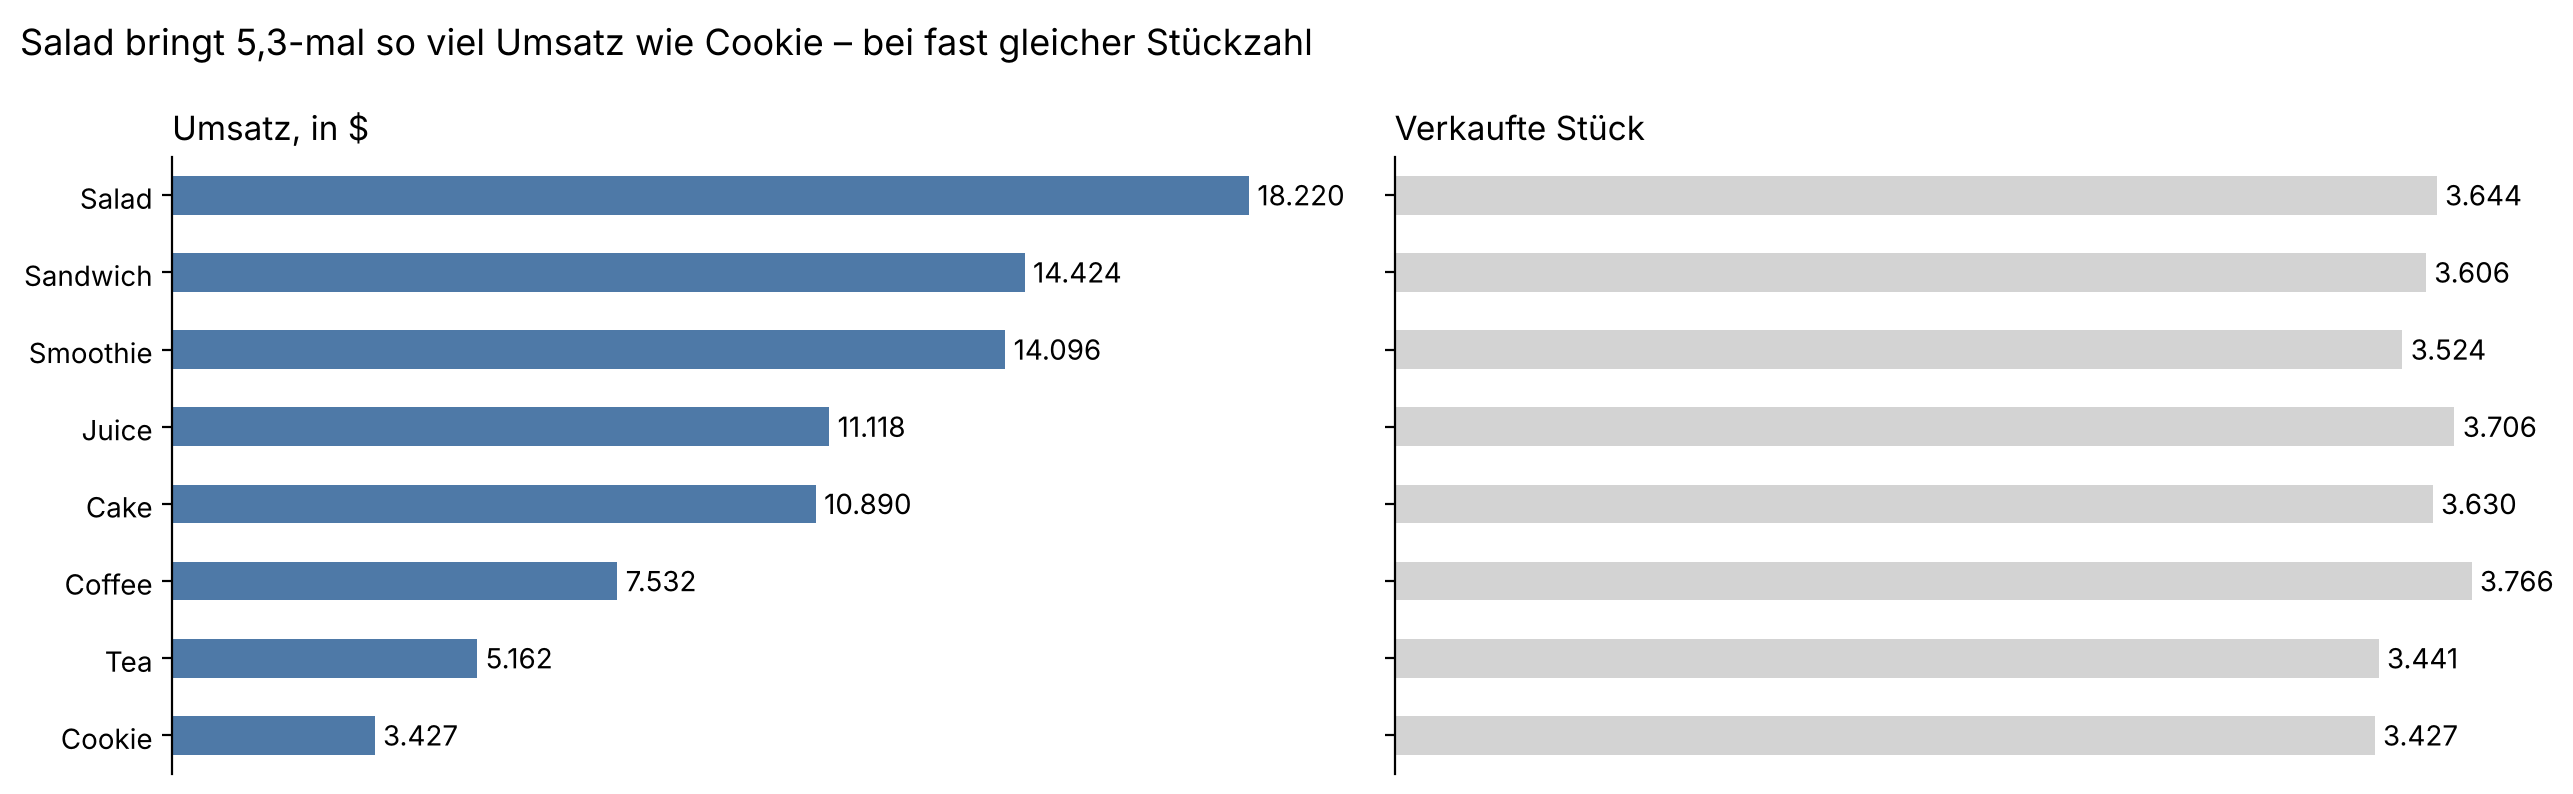

,with_guessed,without_guessed
item,,
Salad,18220.0,18220.0
Sandwich,14424.0,13068.0
Smoothie,14096.0,12776.0
Juice,11118.0,10023.0
Cake,10890.0,9834.0
Coffee,7532.0,7532.0
Tea,5161.5,5161.5
Cookie,3427.0,3427.0


In [18]:
known = df[df["item"] != "Unknown"]
units_by_item = known.groupby("item")["quantity"].sum()
revenue_by_item = known.groupby("item")["total_spent"].sum().sort_values()
units_by_item = units_by_item[revenue_by_item.index]   # same order in both charts

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
revenue_by_item.plot(kind="barh", ax=axes[0], color=BLUE)
axes[0].bar_label(axes[0].containers[0], labels=[de(v) for v in revenue_by_item], padding=3)
axes[0].set_title("Umsatz, in $", loc="left")
units_by_item.plot(kind="barh", ax=axes[1], color=GREY)
axes[1].bar_label(axes[1].containers[0], labels=[de(v) for v in units_by_item], padding=3)
axes[1].set_title("Verkaufte Stück", loc="left")
for ax in axes:
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.set_ylabel("")
fig.suptitle("Salad bringt 5,3-mal so viel Umsatz wie Cookie – bei fast gleicher Stückzahl",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

# robustness: revenue with and without guessed items
without_guessed = df[(df["item"] != "Unknown") & ~df["item_guessed"]]
compare = pd.DataFrame({
    "with_guessed": known.groupby("item")["total_spent"].sum(),
    "without_guessed": without_guessed.groupby("item")["total_spent"].sum(),
}).sort_values("with_guessed", ascending=False)
display(compare)

**Finding:**
- Units are almost equal: 3,427 (Cookie) to 3,766 (Coffee), a 9.9 % gap.
- Revenue differs strongly: Salad $18,220 vs. Cookie $3,427 (5.3×). Salad + Sandwich + Smoothie = 55.1 % of revenue.
- Coffee is #1 by units but #6 by revenue ($7,532): price, not popularity, drives revenue.
- Without the guessed rows the ranking does not change, so the conclusion is robust.

### 3.2 Payment method and location

payment_method
Credit Card       22.9
Cash              23.0
Digital Wallet    23.0
Unknown           31.0
Name: total_spent, dtype: float64

location
Takeaway    29.9
In-store    30.5
Unknown     39.6
Name: total_spent, dtype: float64

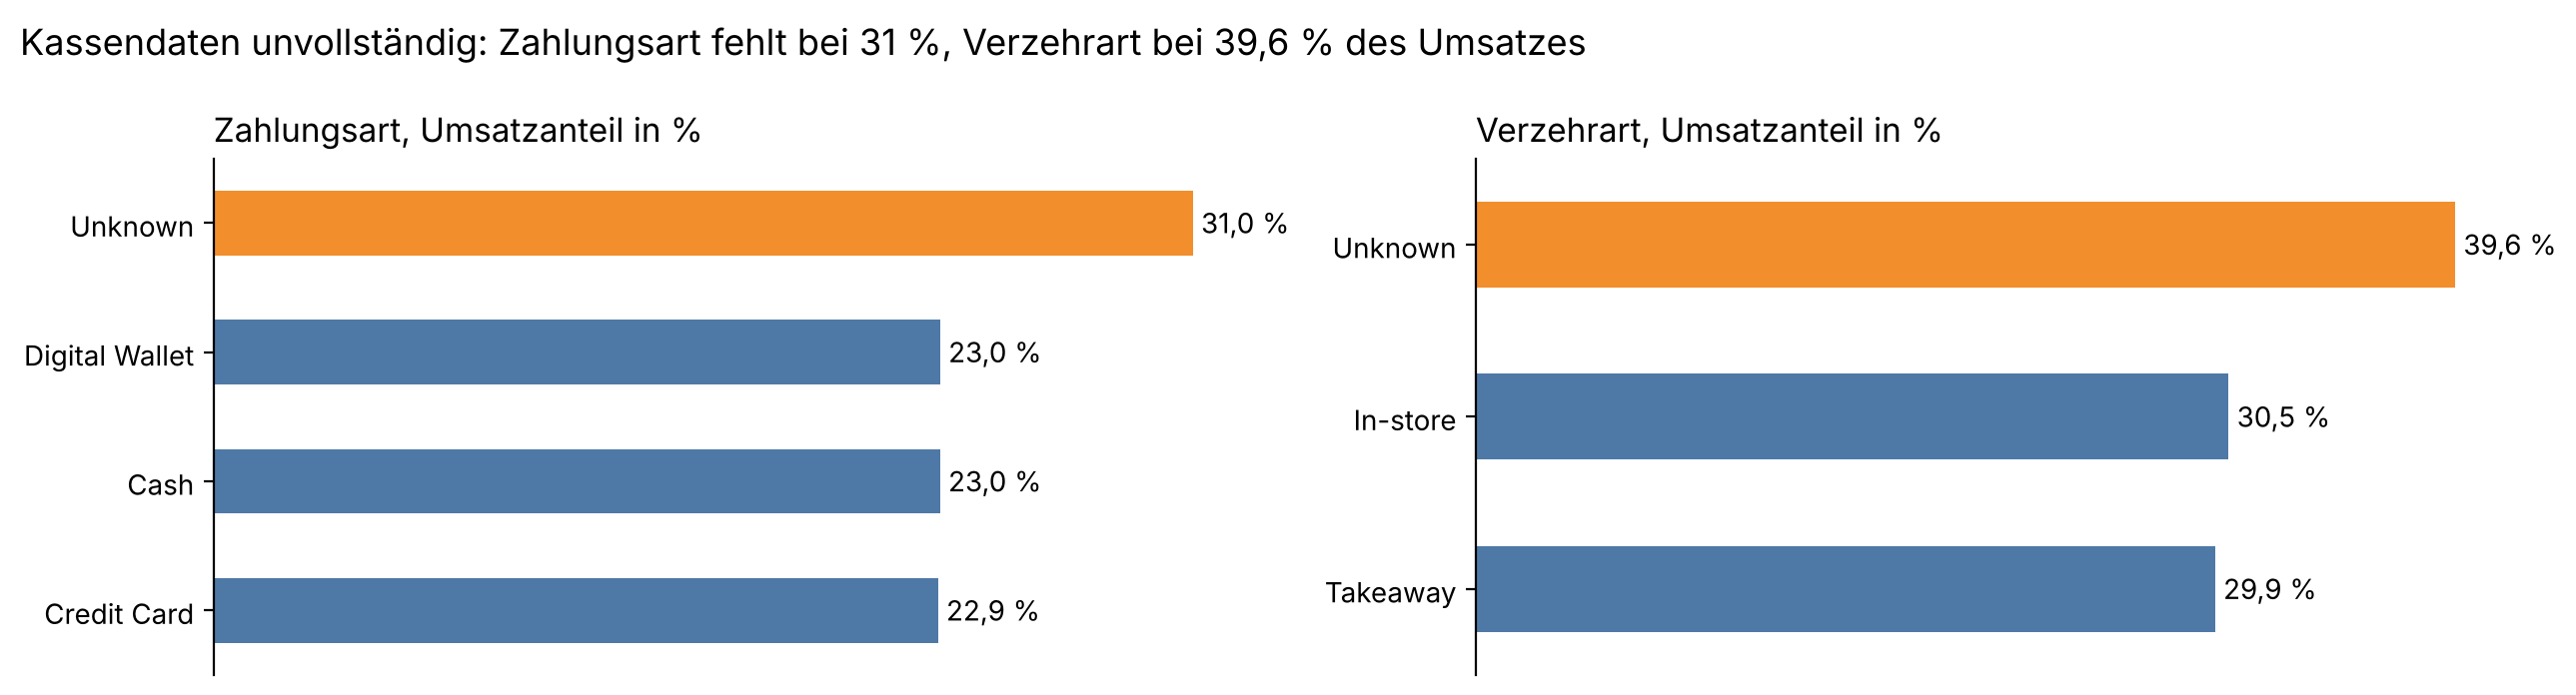

In [19]:
revenue_by_payment = df.groupby("payment_method")["total_spent"].sum()
revenue_by_location = df.groupby("location")["total_spent"].sum()
share_payment = (revenue_by_payment / revenue_by_payment.sum() * 100).sort_values()
share_location = (revenue_by_location / revenue_by_location.sum() * 100).sort_values()
display(share_payment.round(1), share_location.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, s, title in [(axes[0], share_payment, "Zahlungsart"), (axes[1], share_location, "Verzehrart")]:
    s.plot(kind="barh", ax=ax, color=[ORANGE if i == "Unknown" else BLUE for i in s.index])
    ax.bar_label(ax.containers[0], labels=[de(v, 1) + " %" for v in s], padding=3)
    ax.set_title(title + ", Umsatzanteil in %", loc="left")
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.set_ylabel("")
fig.suptitle("Kassendaten unvollständig: Zahlungsart fehlt bei 31 %, Verzehrart bei 39,6 % des Umsatzes",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

known_location = revenue_by_location.drop("Unknown")

**Finding:**
- Unknown: 31.0 % of revenue without payment method, 39.6 % without location.
- Among known values everything is almost equal: cash 23.0 %, digital wallet 23.0 %, credit card 22.9 %; in-store 50.5 % vs. takeaway 49.5 % of known revenue.
- Because 31–40 % is unknown, conclusions on payment and location are indicative only.

### 3.3 Sales over time

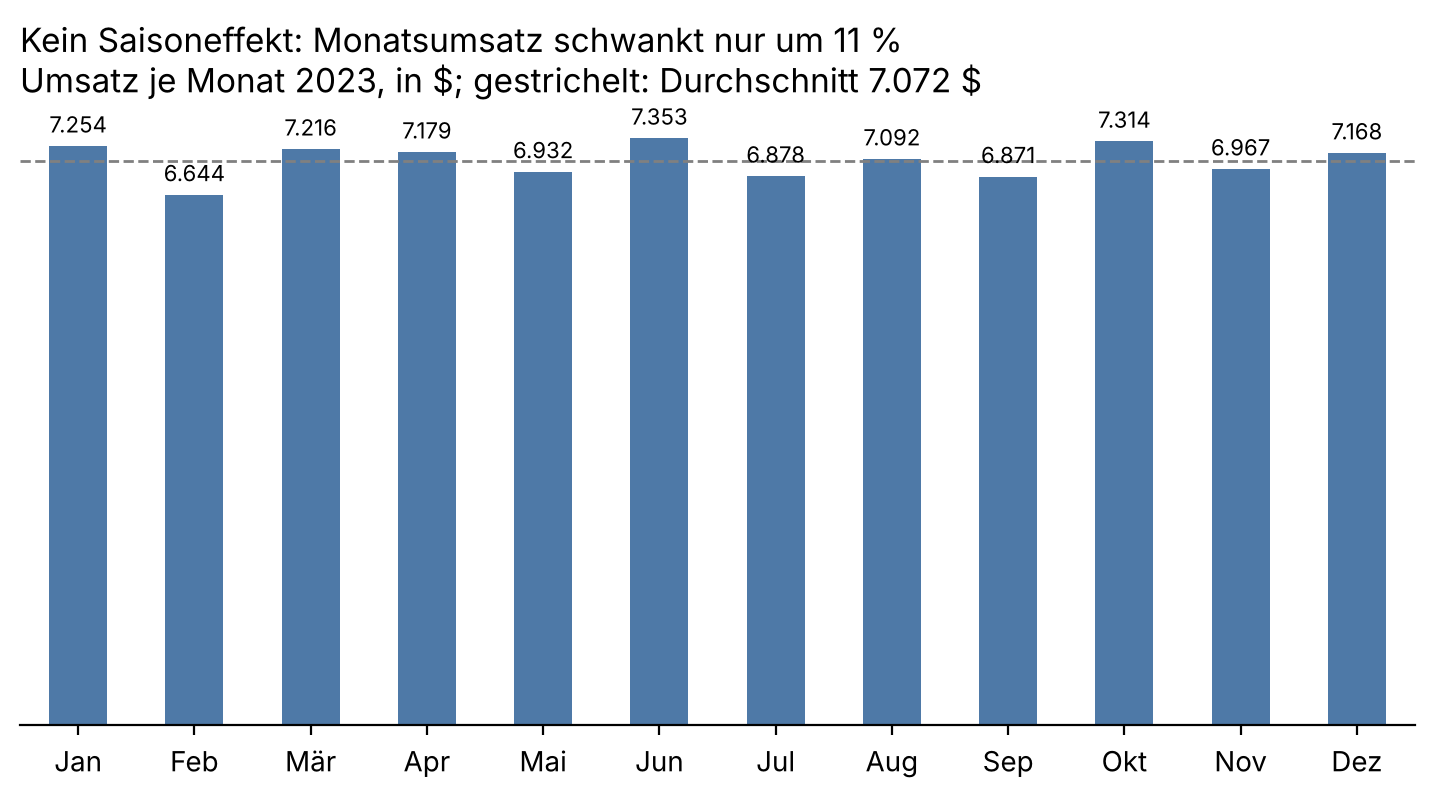

month
Jan    2.6
Feb   -6.1
Mär    2.0
Apr    1.5
Mai   -2.0
Jun    4.0
Jul   -2.8
Aug    0.3
Sep   -2.8
Okt    3.4
Nov   -1.5
Dez    1.4
Name: total_spent, dtype: float64

In [20]:
month_names = {1: "Jan", 2: "Feb", 3: "Mär", 4: "Apr", 5: "Mai", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Dez"}
monthly = df.groupby("month")["total_spent"].sum()
monthly.index = monthly.index.map(month_names)

ax = monthly.plot(kind="bar", rot=0, color=BLUE)
ax.bar_label(ax.containers[0], labels=[de(v) for v in monthly], padding=3, fontsize=8)
plt.axhline(monthly.mean(), color="grey", linestyle="--", linewidth=1)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
plt.title("Kein Saisoneffekt: Monatsumsatz schwankt nur um 11 %\n"
          "Umsatz je Monat 2023, in $; gestrichelt: Durchschnitt " + de(monthly.mean()) + " $", loc="left")
plt.xlabel("")
plt.show()

display(((monthly / monthly.mean() - 1) * 100).round(1))

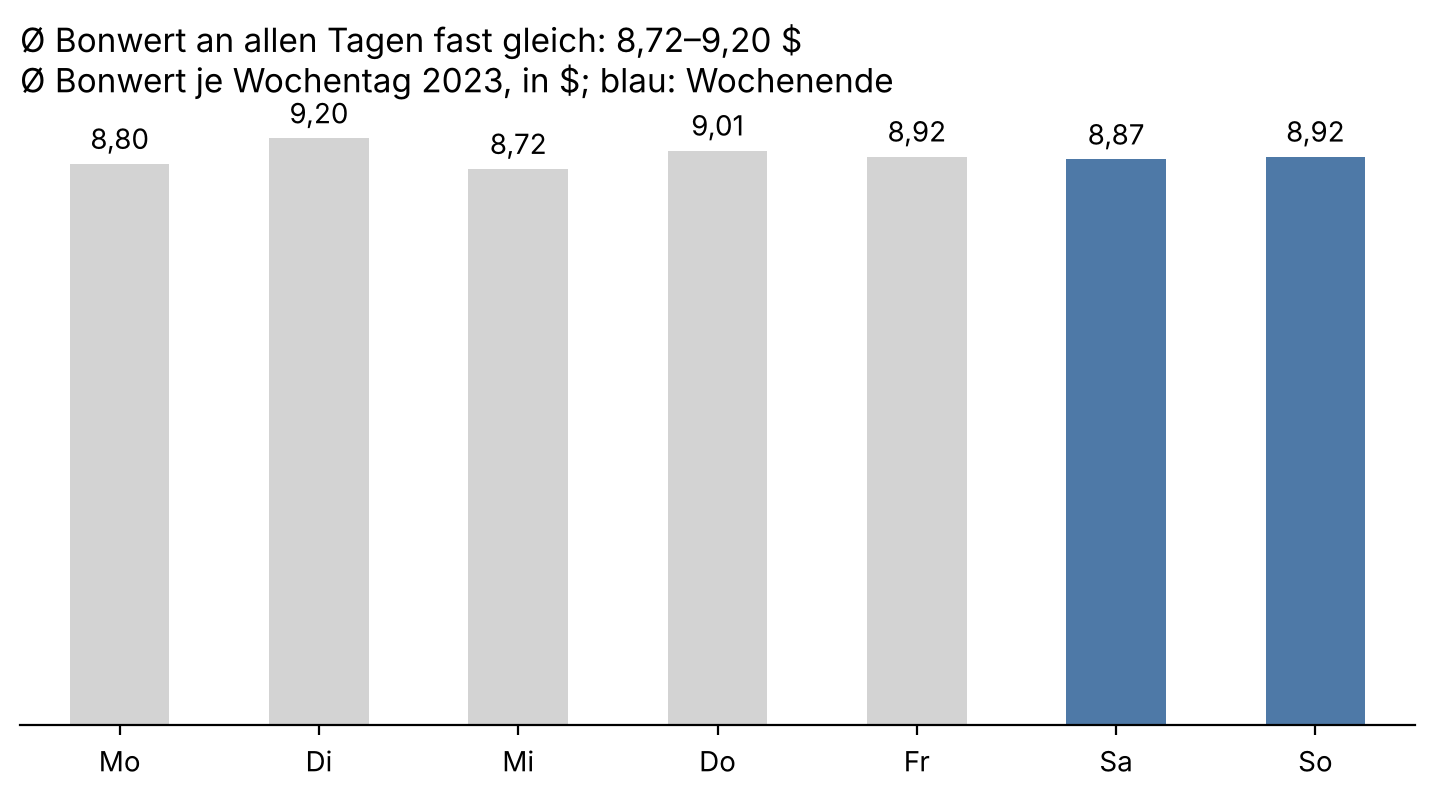

In [21]:
weekday_names = {0: "Mo", 1: "Di", 2: "Mi", 3: "Do", 4: "Fr", 5: "Sa", 6: "So"}
avg_check = df.groupby("weekday")["total_spent"].mean()
avg_check.index = avg_check.index.map(weekday_names)

colors = [BLUE if d in ["Sa", "So"] else GREY for d in avg_check.index]
ax = avg_check.plot(kind="bar", rot=0, color=colors)
ax.bar_label(ax.containers[0], labels=[de(v, 2) for v in avg_check], padding=3)
ax.set_yticks([]); ax.spines["left"].set_visible(False)
plt.title("Ø Bonwert an allen Tagen fast gleich: 8,72–9,20 $\n"
          "Ø Bonwert je Wochentag 2023, in $; blau: Wochenende", loc="left")
plt.xlabel("")
plt.show()

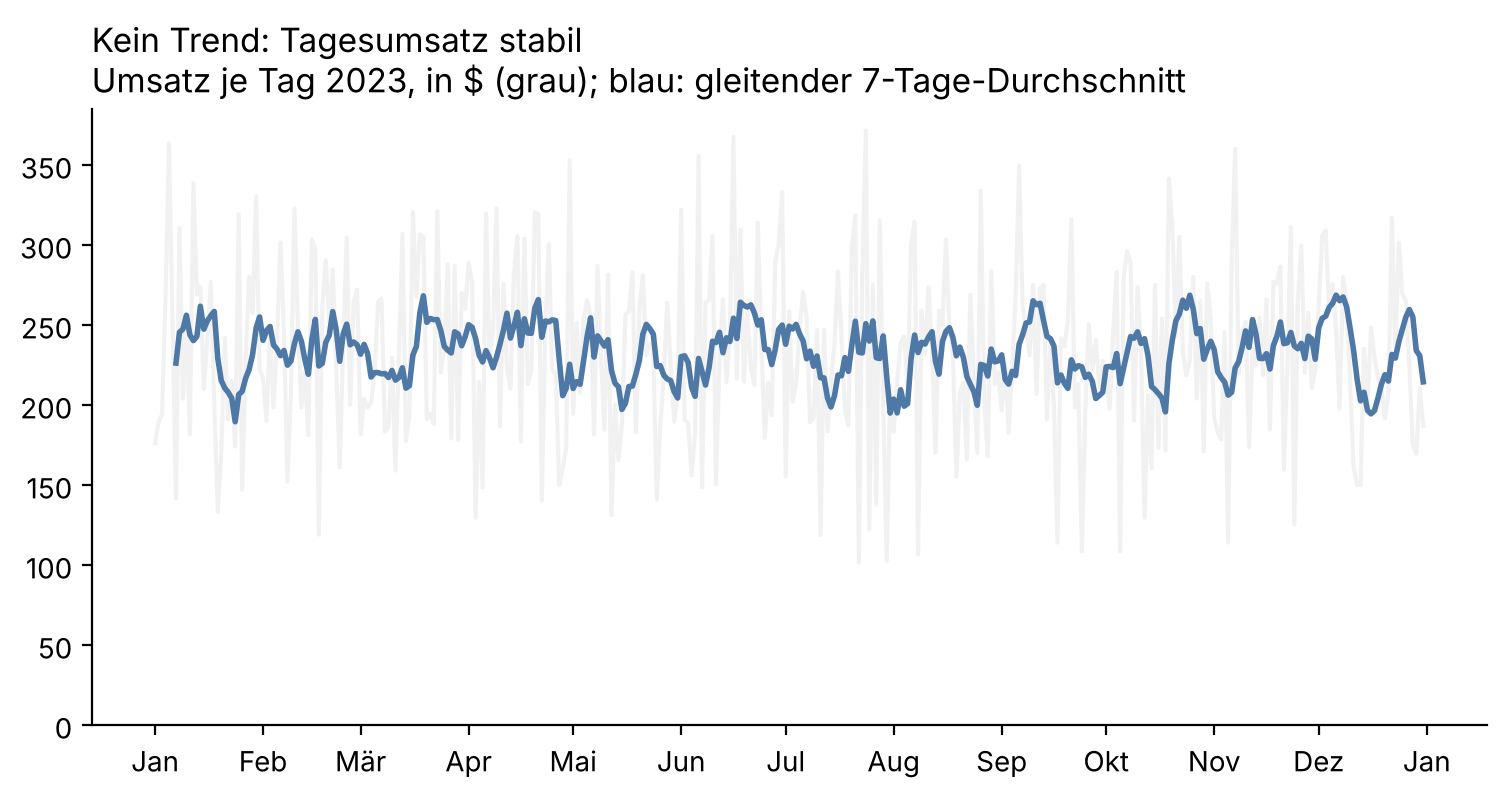

In [22]:
import matplotlib.dates as mdates
daily = df.groupby("transaction_date")["total_spent"].sum()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, alpha=0.3, color=GREY)
ax.plot(daily.index, daily.rolling(7).mean().values, linewidth=2, color=BLUE)
# German month labels on the date axis
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(plt.FuncFormatter(
    lambda x, pos: month_names[mdates.num2date(x).month]))
plt.title("Kein Trend: Tagesumsatz stabil\n"
          "Umsatz je Tag 2023, in $ (grau); blau: gleitender 7-Tage-Durchschnitt", loc="left")
plt.xlabel("")
plt.ylim(bottom=0)
plt.show()

**Finding:**
- Best month June $7,353 (+4.0 % vs. average month $7,072), weakest February $6,644 (−6.1 %, only 28 days).
- Average check per weekday $8.72 (Wed) – $9.20 (Tue); weekend (Sat $8.87, Sun $8.92) is within the weekday range.
- The 7-day average stays at ≈ $200–270 per day without growth or decline: no seasonal trend in 2023.

### 3.4 Outliers

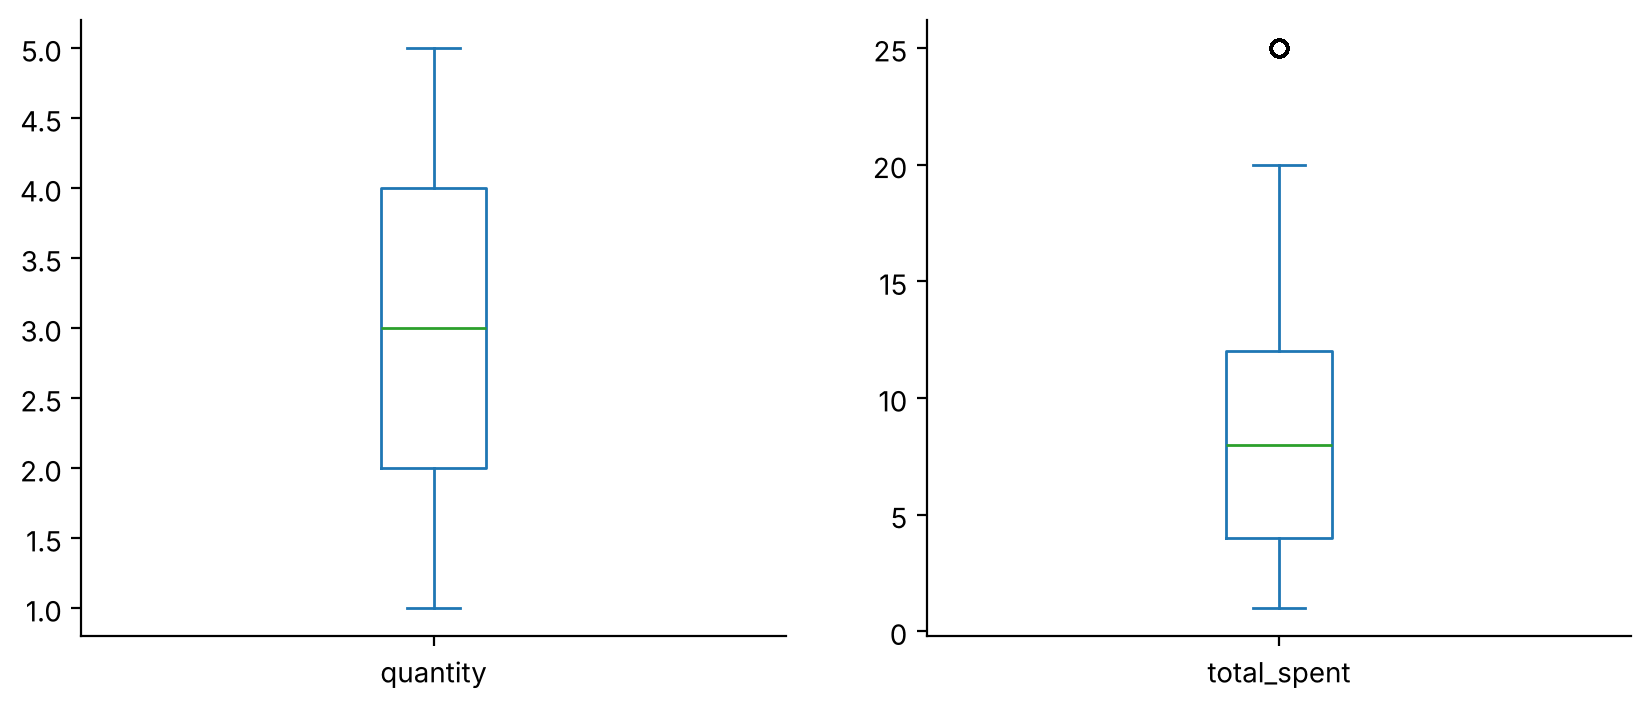

Q1: 4.0 | Q3: 12.0 | IQR: 8.0
Normal range: -8.0 - 24.0
Outliers: 259


,,,count,first
item,quantity,price_per_unit,,
Salad,5,5.0,259,25.0


In [23]:
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

q1 = df["total_spent"].quantile(0.25)
q3 = df["total_spent"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["total_spent"] < low) | (df["total_spent"] > high)]
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Normal range:", low, "-", high)
print("Outliers:", len(outliers))
display(outliers.groupby(["item", "quantity", "price_per_unit"])["total_spent"].agg(["count", "first"]))

**Decision:** IQR range is −8 to 24 $ (Q1 = 4, Q3 = 12). All 259 outliers are the same purchase:
5 × Salad × $5 = $25, the largest possible regular check. Not an error, so they are kept;
removing them would understate the revenue of the best-selling item.

### 3.5 Correlations

In [24]:
corr = df[["quantity", "price_per_unit", "total_spent"]].corr()
display(corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))

,quantity,price_per_unit,total_spent
quantity,1.00,0.01,0.70
price_per_unit,0.01,1.00,0.65
total_spent,0.70,0.65,1.00


| Pair | Correlation | Meaning |
|---|---|---|
| quantity ↔ total_spent | 0.70 | strong: more units → higher check |
| price_per_unit ↔ total_spent | 0.65 | moderate/strong: pricier item → higher check |
| quantity ↔ price_per_unit | 0.01 | none: expensive items are bought in the same quantities as cheap ones |

Revenue can be increased in two ways: more units per check or more expensive items.

---
# 4 · Summary for the café owner

In [25]:
total_revenue = df["total_spent"].sum()
n_transactions = len(df)
average_check = df["total_spent"].mean()
top_item_original = without_guessed.groupby("item")["total_spent"].sum().idxmax()
top_payment = df[df["payment_method"] != "Unknown"].groupby("payment_method")["total_spent"].sum().idxmax()
location_share = (known_location / known_location.sum() * 100).round(1)

print("CAFE SALES 2023: SUMMARY")
print("Total revenue, $:", round(total_revenue, 2))
print("Transactions:", n_transactions)
print("Average check, $:", round(average_check, 2))
print("Top item by revenue (original data):", top_item_original)
print("Top payment method (known only):", top_payment)
print("Revenue share by location, %:", location_share.to_dict())

CAFE SALES 2023: SUMMARY
Total revenue, $: 84868.5
Transactions: 9514
Average check, $: 8.92
Top item by revenue (original data): Salad
Top payment method (known only): Digital Wallet
Revenue share by location, %: {'In-store': 50.5, 'Takeaway': 49.5}


**Key findings**
1. 2023: revenue $84,868.50 from 9,514 transactions, average check $8.92.
2. Revenue comes from pricier items: Salad $18,220 (21.5 %); Salad + Sandwich + Smoothie = 55.1 %. Coffee sells most often (3,766 units) but brings only $7,532.
3. Payment method and location barely matter: shares are almost equal (cash / card / wallet ≈ 23 % each; in-store / takeaway 50.5 / 49.5 %).
4. Sales are stable over the year: months within −6.1 % to +4.0 % of the average, weekend check equals weekday check.

**Recommendations**
- Promote higher-priced items (Salad, Sandwich, Smoothie), e.g. a "coffee + salad/sandwich" combo, instead of discounts on cheap items.
- Plan staff and purchasing evenly: no pronounced peaks by month or weekday.
- Make payment method and location mandatory at the till: today 31 % and 39.6 % of revenue lack this information.

**Data limitations**
- Synthetic training dataset (Kaggle).
- 486 rows (4.9 %) removed as not restorable (10,000 − 9,514).
- Part of the items at $3.00 and $4.00 were guessed proportionally (`item_guessed`); the item ranking does not change without them.
- Conclusions on payment method and location are indicative because of the high share of unknown values.